**Problem 2c**

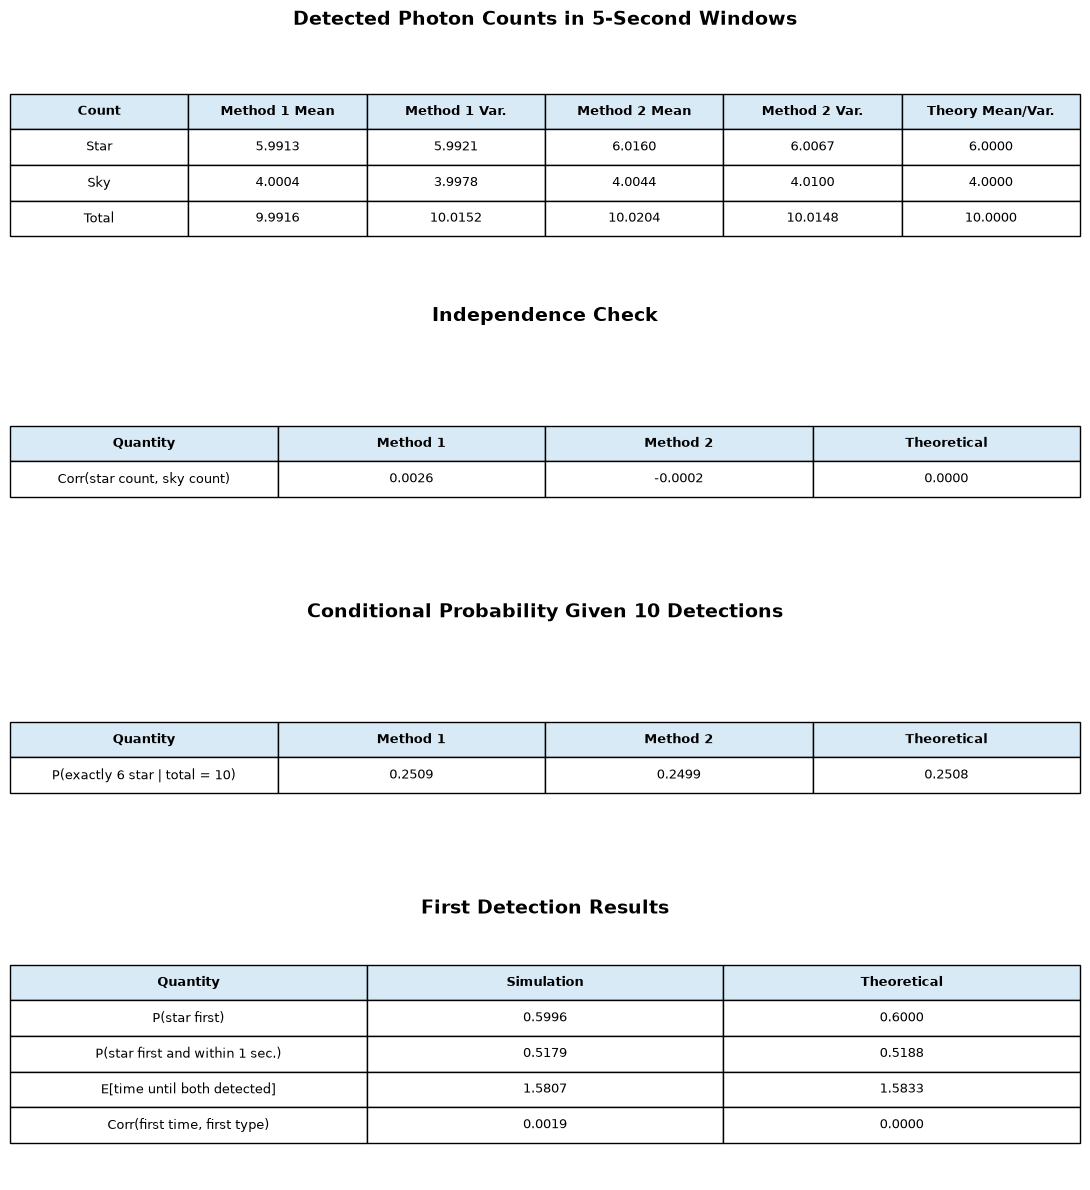

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


rng = np.random.default_rng(4100)

R = 200000
window = 5
q = 0.4

star_rate = 3
sky_rate = 2

detected_star_rate = q * star_rate
detected_sky_rate = q * sky_rate


#generate photons, detect each with probability 0.4

emitted_star = rng.poisson(star_rate * window, R)
emitted_sky = rng.poisson(sky_rate * window, R)

star_1 = rng.binomial(emitted_star, q)
sky_1 = rng.binomial(emitted_sky, q)

total_1 = star_1 + sky_1


#gen detected photons directly

star_2 = rng.poisson(detected_star_rate * window, R)
sky_2 = rng.poisson(detected_sky_rate * window, R)

total_2 = star_2 + sky_2


#summary stats

mean_star_1 = np.mean(star_1)
var_star_1 = np.var(star_1, ddof=1)

mean_sky_1 = np.mean(sky_1)
var_sky_1 = np.var(sky_1, ddof=1)

mean_total_1 = np.mean(total_1)
var_total_1 = np.var(total_1, ddof=1)

mean_star_2 = np.mean(star_2)
var_star_2 = np.var(star_2, ddof=1)

mean_sky_2 = np.mean(sky_2)
var_sky_2 = np.var(sky_2, ddof=1)

mean_total_2 = np.mean(total_2)
var_total_2 = np.var(total_2, ddof=1)

correlation_1 = np.corrcoef(star_1, sky_1)[0, 1]
correlation_2 = np.corrcoef(star_2, sky_2)[0, 1]


#prob of exactly 6 star photons given 10 total detections

condition_1 = total_1 == 10
condition_2 = total_2 == 10

probability_6_star_1 = np.mean(star_1[condition_1] == 6)
probability_6_star_2 = np.mean(star_2[condition_2] == 6)

theoretical_6_star = (
    210 * (0.6 ** 6) * (0.4 ** 4)
)


#first detection times
first_star = rng.exponential(
    1 / detected_star_rate,
    R
)

first_sky = rng.exponential(
    1 / detected_sky_rate,
    R
)

star_first = first_star < first_sky
first_detection_time = np.minimum(first_star, first_sky)

both_detected_time = np.maximum(first_star, first_sky)

probability_star_first = np.mean(star_first)

probability_star_first_within_1 = np.mean(
    star_first & (first_star <= 1)
)

mean_both_detected_time = np.mean(both_detected_time)

first_type = star_first.astype(int)

time_type_correlation = np.corrcoef(
    first_detection_time,
    first_type
)[0, 1]


#theoretical values

theoretical_star_first = 0.6

theoretical_star_first_within_1 = (
    0.6 * (1 - np.exp(-2))
)

theoretical_mean_both = (
    1 / 1.2
    + 1 / 0.8
    - 1 / 2
)


#tables

fig, axes = plt.subplots(4, 1, figsize=(11, 12))

table_data = [
    (
        "Detected Photon Counts in 5-Second Windows",
        [
            "Count",
            "Method 1 Mean",
            "Method 1 Var.",
            "Method 2 Mean",
            "Method 2 Var.",
            "Theory Mean/Var."
        ],
        [
            [
                "Star",
                f"{mean_star_1:.4f}",
                f"{var_star_1:.4f}",
                f"{mean_star_2:.4f}",
                f"{var_star_2:.4f}",
                "6.0000"
            ],
            [
                "Sky",
                f"{mean_sky_1:.4f}",
                f"{var_sky_1:.4f}",
                f"{mean_sky_2:.4f}",
                f"{var_sky_2:.4f}",
                "4.0000"
            ],
            [
                "Total",
                f"{mean_total_1:.4f}",
                f"{var_total_1:.4f}",
                f"{mean_total_2:.4f}",
                f"{var_total_2:.4f}",
                "10.0000"
            ]
        ]
    ),
    (
        "Independence Check",
        ["Quantity", "Method 1", "Method 2", "Theoretical"],
        [
            [
                "Corr(star count, sky count)",
                f"{correlation_1:.4f}",
                f"{correlation_2:.4f}",
                "0.0000"
            ]
        ]
    ),
    (
        "Conditional Probability Given 10 Detections",
        ["Quantity", "Method 1", "Method 2", "Theoretical"],
        [
            [
                "P(exactly 6 star | total = 10)",
                f"{probability_6_star_1:.4f}",
                f"{probability_6_star_2:.4f}",
                f"{theoretical_6_star:.4f}"
            ]
        ]
    ),
    (
        "First Detection Results",
        ["Quantity", "Simulation", "Theoretical"],
        [
            [
                "P(star first)",
                f"{probability_star_first:.4f}",
                f"{theoretical_star_first:.4f}"
            ],
            [
                "P(star first and within 1 sec.)",
                f"{probability_star_first_within_1:.4f}",
                f"{theoretical_star_first_within_1:.4f}"
            ],
            [
                "E[time until both detected]",
                f"{mean_both_detected_time:.4f}",
                f"{theoretical_mean_both:.4f}"
            ],
            [
                "Corr(first time, first type)",
                f"{time_type_correlation:.4f}",
                "0.0000"
            ]
        ]
    )
]

for ax, (title, columns, rows) in zip(axes, table_data):
    ax.axis("off")
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)

    result_table = ax.table(
        cellText=rows,
        colLabels=columns,
        cellLoc="center",
        loc="center"
    )

    result_table.auto_set_font_size(False)
    result_table.set_fontsize(9)
    result_table.scale(1, 1.7)

    for column in range(len(columns)):
        result_table[(0, column)].set_facecolor("#D9EAF7")
        result_table[(0, column)].set_text_props(
            fontweight="bold"
        )

plt.tight_layout()
plt.savefig(
    "2c_results_tables.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()